In [1]:
# Loading Basic Libraries 
import os
import gc   # No Version
from pathlib import Path

import random
import six
import sys
import warnings

import dataclasses
from dataclasses import dataclass, field
from typing import Dict, Any, Tuple, Union, List, Optional, Mapping
from tqdm import tqdm
from tqdm.notebook import tqdm

import yaml
import pickle

In [2]:
# Loading Data Processing Libraries 
import numpy as np
import pandas as pd

from logging import getLogger

In [3]:
# Loading Visualization Libraries 
from IPython.core.display import display, HTML
import matplotlib.pyplot as plt
import matplotlib.patches as ptc
# import seaborn as sns

# from plotly import tools, subplots
# import plotly.offline as py

# import plotly.graph_objs as go
# import plotly.express as px
# import plotly.figure_factory as ff
# import plotly.io as pio

/tmp/ipykernel_2061/3356634764.py:2: DeprecationWarning: Importing display from IPython.core.display is deprecated since IPython 7.14, please import from IPython display
  from IPython.core.display import display, HTML


In [4]:
# Loading Imaging Libraries 
import pydicom as pdc
from pydicom.pixel_data_handlers.util import apply_voi_lut
import cv2
# import albumentations as A

In [5]:
# Loading Statistics Libraries 
import scipy as sp

# Loading Models Libraries 
from sklearn import preprocessing
from sklearn.model_selection import StratifiedKFold, KFold
# import lightgbm as lgb
import xgboost as xgb
# import catboost as cb

import torch
import torch.nn.functional as F
from torch import nn
from torch.nn import Linear
from torch import nn, optim
from torch.utils.data.dataloader import DataLoader
from torch.utils.data.dataset import Dataset

# from ignite.engine import Events, Engine

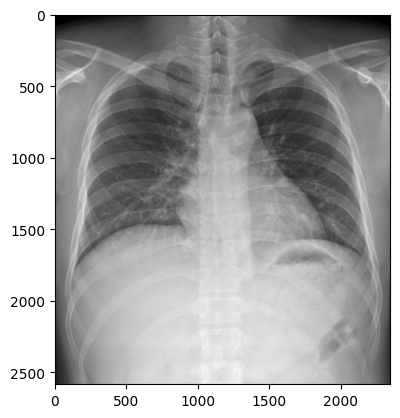

In [6]:
from pydicom import dcmread

ds = dcmread("../vu2/test/002a34c58c5b758217ed1f584ccbcfe9.dicom")

arr = ds.pixel_array

plt.imshow(arr, cmap="gray")
plt.show()

In [7]:
import pandas as pd
import random
from torchvision import transforms

class VinBigDataDataset(Dataset):
    def __init__(self, csv_file, img_dir, transform=None, num_samples=300):
        self.annotations = pd.read_csv(csv_file)
        self.img_dir = img_dir
        self.transform = transform
        
        # Randomly sample the specified number of samples
#         self.annotations = self.annotations.sample(n=num_samples, random_state=42).reset_index(drop=True)

    def __len__(self):
        return len(self.annotations)

    def __getitem__(self, idx):
        img_path = os.path.join(self.img_dir, self.annotations.iloc[idx, 0] + ".dicom")
        dicom_image = pydicom.dcmread(img_path)
        
        # Convert to uint8 by scaling the pixel values
        img = dicom_image.pixel_array
        img = img.astype(np.uint8)  # Convert uint16 to uint8 by truncation

        # Optionally normalize the pixel values to the [0, 255] range
        img = cv2.normalize(img, None, 0, 255, cv2.NORM_MINMAX)

        img = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)  # Convert to RGB
        img = cv2.resize(img, (224, 224))  # Resize for VGG16

        if self.transform:
            img = self.transform(img)

        label = int(self.annotations.iloc[idx, 2])  # class_id
        return img, label

In [8]:
# Hyperparameters and configuration
num_classes = 15  # 14 abnormalities + "No finding"
batch_size = 16
learning_rate = 0.001
num_epochs = 2

# Transformations for DICOM images
transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# Dataset paths
train_csv = "../vu2/train.csv"
train_img_dir = "../vu2/test/"
test_img_dir = "../vu2/test/"

In [9]:
from torch.utils.data import random_split
full_dataset = VinBigDataDataset(
    csv_file='../vu2/train.csv',
    img_dir='../vu2/train',
    transform=transform,
    num_samples=300
)

# # Set the random seed for reproducibility
# random_seed = 42

# # Define split sizes for train, validation, and test
# train_size = int(0.6 * len(full_dataset))  # 60% for training
# val_size = int(0.2 * len(full_dataset))    # 20% for validation
# test_size = len(full_dataset) - train_size - val_size  # Remaining 20% for testing

# # Split the dataset into train, validation, and test sets
# train_dataset, val_dataset, test_dataset = random_split(
#     full_dataset, 
#     [train_size, val_size, test_size], 
#     generator=torch.Generator().manual_seed(random_seed)  # Use the random seed
# )

# # Save each split to a file using pickle
# with open("../vu2/CXR/train_dataset.pkl", "wb") as f:
#     pickle.dump(train_dataset, f)

# with open("../vu2/CXR/val_dataset.pkl", "wb") as f:
#     pickle.dump(val_dataset, f)

# with open("../vu2/CXR/test_dataset.pkl", "wb") as f:
#     pickle.dump(test_dataset, f)

# print("Datasets saved to files: train_dataset.pkl, val_dataset.pkl, and test_dataset.pkl.")

with open("../vu2/CXR/train_dataset.pkl", "rb") as f:
    train_dataset = pickle.load(f)

with open("../vu2/CXR/val_dataset.pkl", "rb") as f:
    val_dataset = pickle.load(f)

with open("../vu2/CXR/test_dataset.pkl", "rb") as f:
    test_dataset = pickle.load(f)

# DataLoaders for training and validation
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)


# Display dataset sizes
print(f"Train dataset size: {len(train_dataset)}")
print(f"Validation dataset size: {len(val_dataset)}")
print(f"Test dataset size: {len(test_dataset)}")

Train dataset size: 40748
Validation dataset size: 13582
Test dataset size: 13584


In [110]:
# # Split the dataset into train, validation, and test sets
# random_seed = 42
# annotations = pd.read_csv('../vu2/train.csv')
# train_size = int(0.6 * len(annotations))  # 60% for training
# val_size = int(0.2 * len(annotations))    # 20% for validation
# test_size = len(annotations) - train_size - val_size  # Remaining 20% for testing
# indices = list(range(len(annotations)))
# train_dataset_csv, val_dataset_csv, test_dataset_csv = random_split(
#     indices, 
#     [train_size, val_size, test_size], 
#     generator=torch.Generator().manual_seed(random_seed)  # Use the random seed
# )

In [111]:
# # Save each split to a file using pickle
# with open("../vu2/CXR/train_dataset_annotations.pkl", "wb") as f:
#     pickle.dump(train_dataset_csv, f)

# with open("../vu2/CXR/val_dataset_annotations.pkl", "wb") as f:
#     pickle.dump(val_dataset_csv, f)

# with open("../vu2/CXR/test_dataset_annotations.pkl", "wb") as f:
#     pickle.dump(test_dataset_csv, f)

In [117]:
with open("../vu2/CXR/train_dataset_annotations.pkl", "rb") as f:
    train_dataset_csv = pickle.load(f)

with open("../vu2/CXR/val_dataset_annotations.pkl", "rb") as f:
    val_dataset_csv = pickle.load(f)

with open("../vu2/CXR/test_dataset_annotations.pkl", "rb") as f:
    test_dataset_csv = pickle.load(f)

In [129]:
val_annotations = annotations.iloc[val_dataset_csv.indices]
test_annotations = annotations.iloc[test_dataset_csv.indices]

,image_id,class_name,class_id,rad_id,x_min,y_min,x_max,y_max
5607,6747991aa8970e35ec44fe90b309d627,Lung Opacity,7,R9,358.0,1654.0,939.0,1855.0
46090,e60ce67640c934d4fb3bcac5b334983d,Other lesion,9,R12,1108.0,841.0,1545.0,1890.0
21620,f40c08b38fce6f2b77c6019d34521357,Nodule/Mass,8,R8,185.0,1548.0,271.0,1622.0
19939,19f08bdb301a4041b98258cf9a5aeafb,No finding,14,R13,NaN,NaN,NaN,NaN
42450,3dead8495b3fdcdde5912953e520b303,Pleural thickening,11,R9,343.0,1564.0,441.0,1688.0
...,...,...,...,...,...,...,...,...
17829,51eb9c41906d5d46d35740f53d37ab49,Infiltration,6,R10,2059.0,1544.0,2635.0,1985.0
1588,d23024cde82d22b8e1cf899c3c0207c7,Cardiomegaly,3,R10,739.0,1595.0,1732.0,1882.0
46210,0e093fa90e5be5666cd396d722cc84ac,Pleural thickening,11,R9,1778.0,447.0,1876.0,487.0
55921,16fbd1b86994c47ddd120cf5d410033e,Aortic enlargement,0,R8,1333.0,650.0,1547.0,876.0


In [104]:
# import torch
# import torchvision.models as models

# # Model, loss, and optimizer
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# # Define the number of output classes

# # Load the pretrained ResNet-50 model
# model = models.resnet50(pretrained=True)

# # Modify the final fully connected layer to match the number of classes
# model.fc = torch.nn.Linear(model.fc.in_features, num_classes)

# # Move the model to the appropriate device (GPU or CPU)
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# model = model.to(device)

# print("ResNet-50 model loaded with a custom number of output classes.")

# criterion = nn.CrossEntropyLoss()
# optimizer = optim.Adam(model.parameters(), lr=learning_rate)

In [11]:
# import pydicom
# from tqdm import tqdm

# # Training function
# def train(model, train_loader, criterion, optimizer, num_epochs):
#     model.train()
#     for epoch in range(num_epochs):
#         print('epoch:',epoch)
#         running_loss = 0.0
#         train_loader_tqdm = tqdm(train_loader, desc="Training", leave=True)

#         for images, labels in train_loader_tqdm:
#             images, labels = images.to(device), labels.to(device)

#             # Forward pass
#             outputs = model(images)
#             loss = criterion(outputs, labels)
#             print(loss)

#             # Backward and optimize
#             optimizer.zero_grad()
#             loss.backward()
#             optimizer.step()

#             running_loss += loss.item()

#         print(f'Epoch [{epoch + 1}/{num_epochs}], Loss: {running_loss / len(train_loader):.4f}')

In [12]:
# train(model, train_loader, criterion, optimizer, num_epochs)

## visualize the bboxes

In [25]:
%matplotlib inline

import os
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import rcParams
sns.set(rc={"font.size":9,"axes.titlesize":15,"axes.labelsize":9,
            "axes.titlepad":11, "axes.labelpad":9, "legend.fontsize":7,
            "legend.title_fontsize":7, 'axes.grid' : False})
import cv2
import json
import pandas as pd
import glob
import os.path as osp
# from path import Path
import datetime
import numpy as np
from tqdm.auto import tqdm
import random
import shutil
from sklearn.model_selection import train_test_split

# from ensemble_boxes import *
import warnings
from collections import Counter

import pydicom

In [26]:
train_annotations = pd.read_csv("../vu2/train.csv")
train_annotations.head(5)



,image_id,class_name,class_id,rad_id,x_min,y_min,x_max,y_max
0,50a418190bc3fb1ef1633bf9678929b3,No finding,14,R11,NaN,NaN,NaN,NaN
1,21a10246a5ec7af151081d0cd6d65dc9,No finding,14,R7,NaN,NaN,NaN,NaN
2,9a5094b2563a1ef3ff50dc5c7ff71345,Cardiomegaly,3,R10,691.0,1375.0,1653.0,1831.0
3,051132a778e61a86eb147c7c6f564dfe,Aortic enlargement,0,R10,1264.0,743.0,1611.0,1019.0
4,063319de25ce7edb9b1c6b8881290140,No finding,14,R10,NaN,NaN,NaN,NaN


In [27]:
train_annotations = train_annotations[train_annotations.class_id!=14]
train_annotations['image_path'] = train_annotations['image_id'].map(lambda x:os.path.join('../vu2/train', str(x)+'.dicom'))
train_annotations.head(5)

,image_id,class_name,class_id,rad_id,x_min,y_min,x_max,y_max,image_path
2,9a5094b2563a1ef3ff50dc5c7ff71345,Cardiomegaly,3,R10,691.0,1375.0,1653.0,1831.0,../vu2/train/9a5094b2563a1ef3ff50dc5c7ff71345....
3,051132a778e61a86eb147c7c6f564dfe,Aortic enlargement,0,R10,1264.0,743.0,1611.0,1019.0,../vu2/train/051132a778e61a86eb147c7c6f564dfe....
5,1c32170b4af4ce1a3030eb8167753b06,Pleural thickening,11,R9,627.0,357.0,947.0,433.0,../vu2/train/1c32170b4af4ce1a3030eb8167753b06....
6,0c7a38f293d5f5e4846aa4ca6db4daf1,ILD,5,R17,1347.0,245.0,2188.0,2169.0,../vu2/train/0c7a38f293d5f5e4846aa4ca6db4daf1....
7,47ed17dcb2cbeec15182ed335a8b5a9e,Nodule/Mass,8,R9,557.0,2352.0,675.0,2484.0,../vu2/train/47ed17dcb2cbeec15182ed335a8b5a9e....


In [28]:
# img_size_df = pd.read_csv('../vu2/train_meta.csv', names=['image_id', 'orig_height', 'orig_width'])

# # Merge the original image size information with the training data
# train_annotations = train_annotations.merge(img_size_df, on='image_id', how='left')
# train_annotations.head(5)

In [29]:
imagepaths = train_annotations['image_path'].unique()
print("Number of Images with abnormalities:",len(imagepaths))
anno_count = train_annotations.shape[0]
print("Number of Annotations with abnormalities:", anno_count)

Number of Images with abnormalities: 4394
Number of Annotations with abnormalities: 36096


In [30]:
def plot_img(img, size=(18, 18), is_rgb=True, title="", cmap='gray'):
    plt.figure(figsize=size)
    plt.imshow(img, cmap=cmap)
    plt.suptitle(title)
    plt.show()

def plot_imgs(imgs, cols=2, size=10, is_rgb=True, title="", cmap='gray', img_size=None):
    rows = len(imgs)//cols + 1
    fig = plt.figure(figsize=(cols*size, rows*size))
    for i, img in enumerate(imgs):
        if img_size is not None:
            img = cv2.resize(img, img_size)
        fig.add_subplot(rows, cols, i+1)
        plt.imshow(img, cmap=cmap)
    plt.suptitle(title)
    
def draw_bbox(image, box, label, color):   
    alpha = 0.1
    alpha_box = 0.4
    overlay_bbox = image.copy()
    overlay_text = image.copy()
    output = image.copy()

    text_width, text_height = cv2.getTextSize(label.upper(), cv2.FONT_HERSHEY_SIMPLEX, 0.6, 1)[0]
    cv2.rectangle(overlay_bbox, (box[0], box[1]), (box[2], box[3]),
                color, -1)
    cv2.addWeighted(overlay_bbox, alpha, output, 1 - alpha, 0, output)
    cv2.rectangle(overlay_text, (box[0], box[1]-7-text_height), (box[0]+text_width+2, box[1]),
                (0, 0, 0), -1)
    cv2.addWeighted(overlay_text, alpha_box, output, 1 - alpha_box, 0, output)
    cv2.rectangle(output, (box[0], box[1]), (box[2], box[3]),
                    color, thickness)
    cv2.putText(output, label.upper(), (box[0], box[1]-5),
            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 1, cv2.LINE_AA)
    return output

In [31]:
labels =  [
            "__ignore__",
            "Aortic_enlargement",
            "Atelectasis",
            "Calcification",
            "Cardiomegaly",
            "Consolidation",
            "ILD",
            "Infiltration",
            "Lung_Opacity",
            "Nodule/Mass",
            "Other_lesion",
            "Pleural_effusion",
            "Pleural_thickening",
            "Pneumothorax",
            "Pulmonary_fibrosis"
            ]
viz_labels = labels[1:]

[ 3 10 11  3  3  0] [[ 691. 1375. 1653. 1831.]
 [1789. 1729. 1875. 1992.]
 [1789. 1729. 1875. 1992.]
 [ 692. 1375. 1657. 1799.]
 [ 689. 1313. 1666. 1763.]
 [1052.  715. 1299.  966.]]
[ 0  0  3  3 11  0  3] [[1264.  743. 1611. 1019.]
 [1305.  731. 1613. 1066.]
 [ 948. 1267. 2063. 1672.]
 [ 962. 1331. 2035. 1624.]
 [1592.  452. 1804.  604.]
 [1275.  729. 1612. 1066.]
 [ 952. 1317. 2033. 1723.]]
[11 13 11 13 13 13 11 13 13] [[ 627.  357.  947.  433.]
 [ 511.  508.  950.  762.]
 [1780.  361. 2047.  612.]
 [1793.  757. 1972.  917.]
 [1684.  450. 1916.  739.]
 [ 549.  456.  910.  801.]
 [1856.  412. 2045.  587.]
 [ 529.  440.  771.  741.]
 [1734.  545. 1887.  747.]]
[5 5 8 5 9] [[1347.  245. 2188. 2169.]
 [  87.  196. 1013. 2129.]
 [ 458.  792.  669.  962.]
 [ 161.   56. 2117. 2213.]
 [ 161.   56. 2117. 2213.]]
[8 9 8 9 9 8 7 7] [[ 557. 2352.  675. 2484.]
 [ 557. 2352.  675. 2484.]
 [ 544. 2345.  674. 2485.]
 [1715.  906. 2054. 1387.]
 [1723.  983. 2048. 1398.]
 [ 562. 2346.  663. 2460.]
 [ 

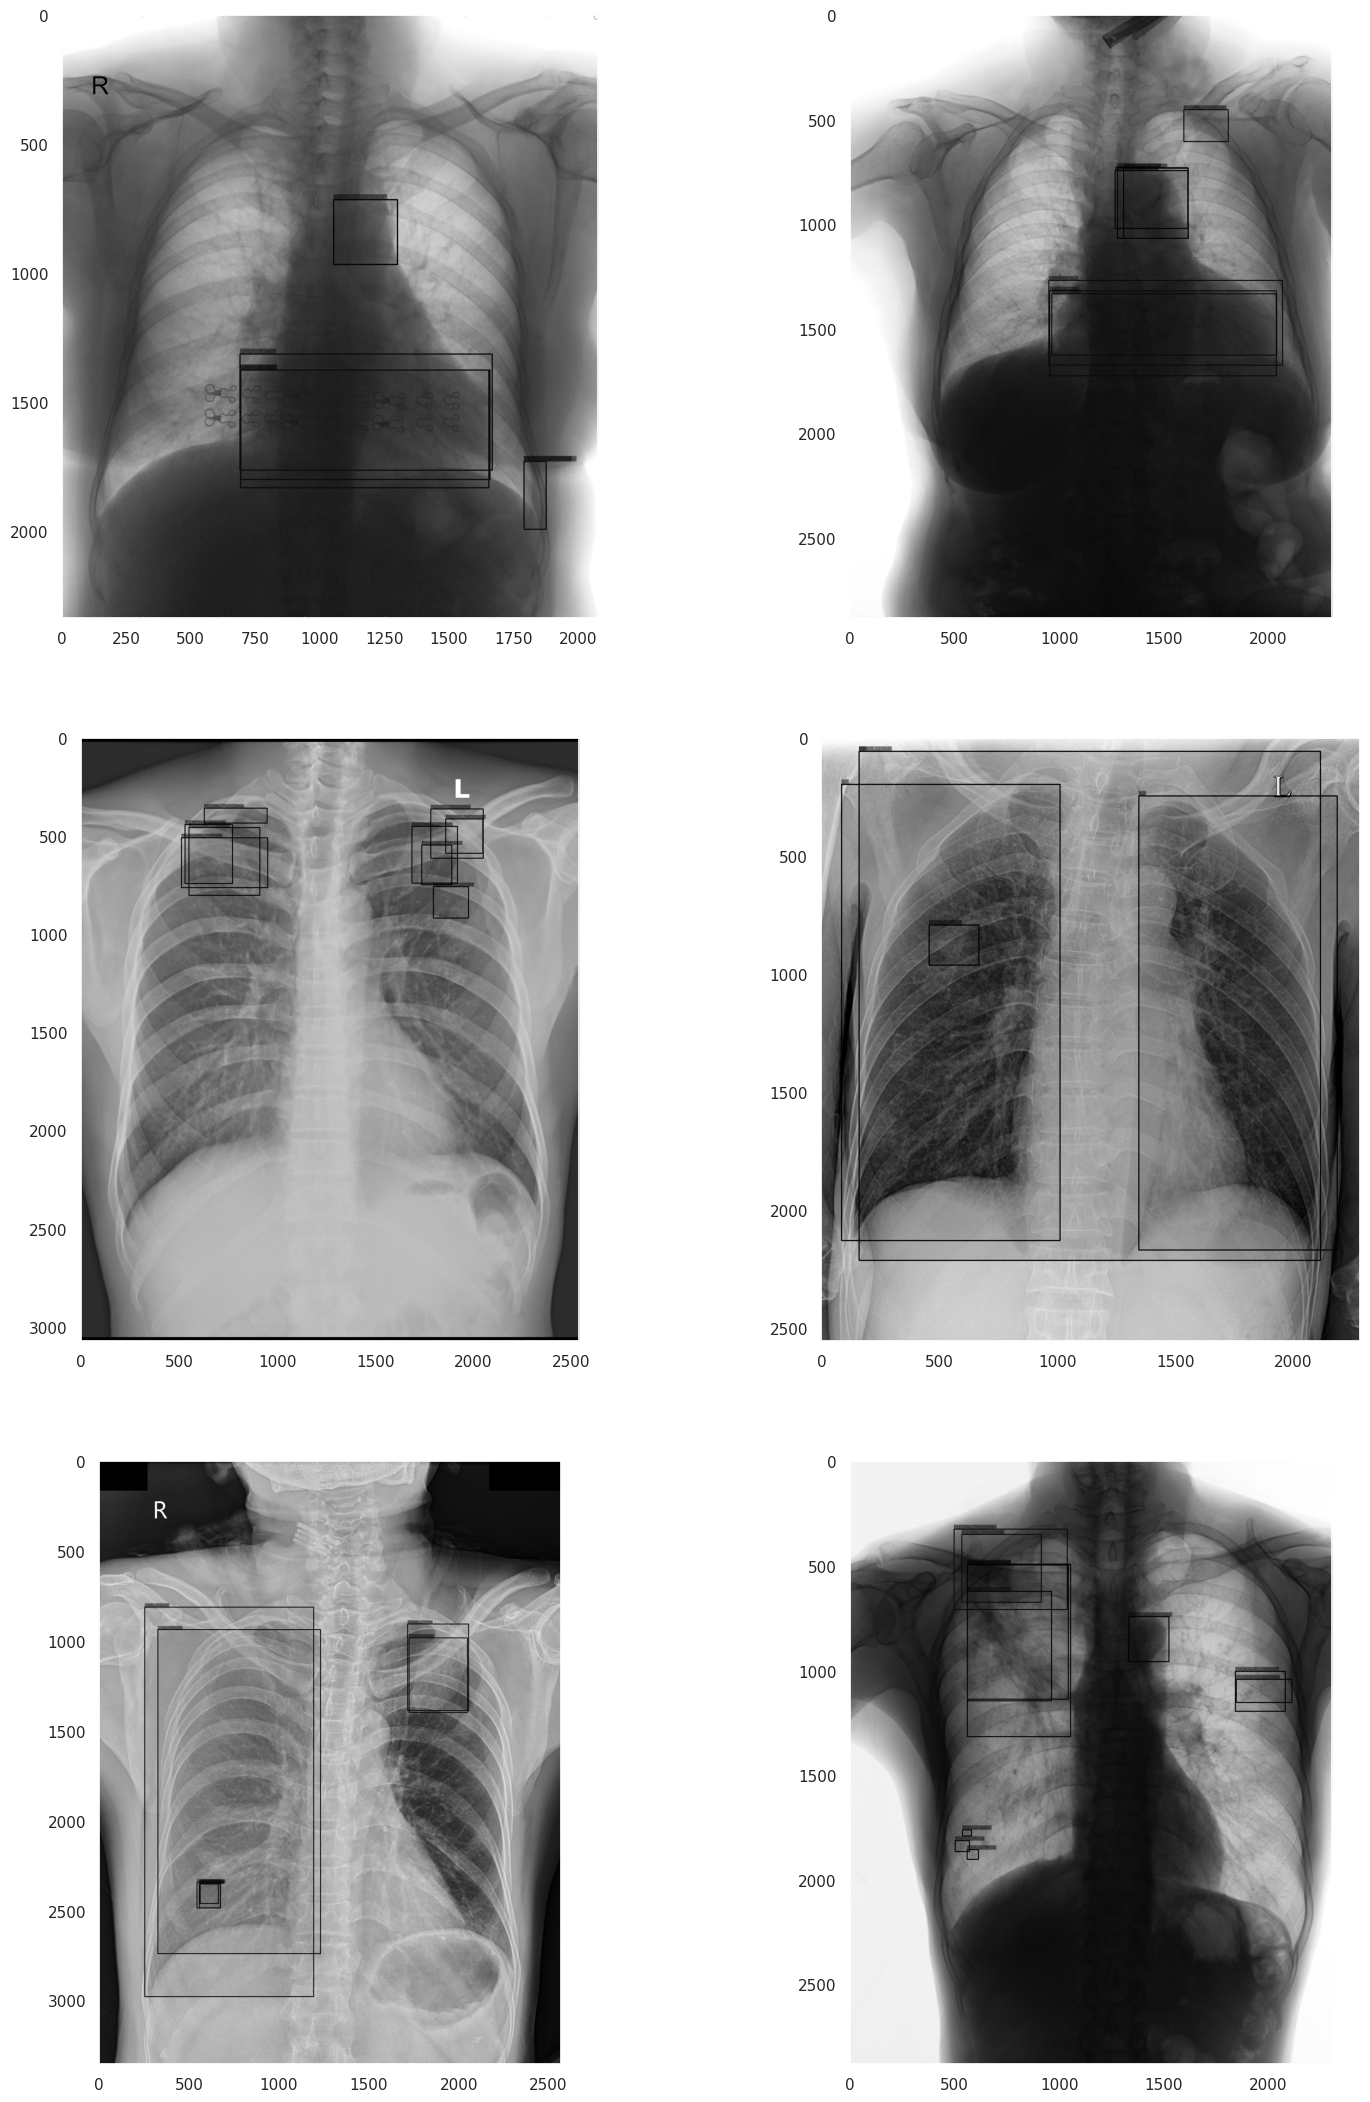

In [55]:
# map label_id to specify color
#label2color = [[random.randint(0,255) for i in range(3)] for class_id in viz_labels]
label2color = [[59, 238, 119], [222, 21, 229], [94, 49, 164], [206, 221, 133], [117, 75, 3],
                 [210, 224, 119], [211, 176, 166], [63, 7, 197], [102, 65, 77], [194, 134, 175],
                 [209, 219, 50], [255, 44, 47], [89, 125, 149], [110, 27, 100]]

thickness = 3
imgs = []

for img_id, path in zip(train_annotations['image_id'][:6], train_annotations['image_path'][:6]):

    boxes = train_annotations.loc[train_annotations['image_id'] == img_id,
                                  ['x_min', 'y_min', 'x_max', 'y_max']].values
    img_labels = train_annotations.loc[train_annotations['image_id'] == img_id, ['class_id']].values.squeeze()
    print(img_labels, boxes)
    

    ds = pydicom.dcmread(path)

    img = ds.pixel_array

#     plt.imshow(arr, cmap="gray")
#     plt.show()

    for label_id, box in zip(img_labels, boxes):
        color = label2color[label_id]
        img = draw_bbox(img, list(np.int_(box)), viz_labels[label_id], color)
    imgs.append(img)

plot_imgs(imgs, size=9, cmap='gray')
plt.show()

Bboxes before nms:
 [[691.0, 1375.0, 1653.0, 1831.0], [1789.0, 1729.0, 1875.0, 1992.0], [1789.0, 1729.0, 1875.0, 1992.0], [692.0, 1375.0, 1657.0, 1799.0], [689.0, 1313.0, 1666.0, 1763.0], [1052.0, 715.0, 1299.0, 966.0]]
Labels before nms:
 [3, 10, 11, 3, 3, 0]
Counter({3: 3, 10: 1, 11: 1, 0: 1})
Bboxes after nms:
 [[689.0, 1313.0, 1666.0, 1763.0], [1789.0, 1729.0, 1875.0, 1992.0], [1789.0, 1729.0, 1875.0, 1992.0], [1052.0, 715.0, 1299.0, 966.0]]
Labels after nms:
 [3, 10, 11, 0]

Bboxes before nms:
 [[1264.0, 743.0, 1611.0, 1019.0], [1305.0, 731.0, 1613.0, 1066.0], [948.0, 1267.0, 2063.0, 1672.0], [962.0, 1331.0, 2035.0, 1624.0], [1592.0, 452.0, 1804.0, 604.0], [1275.0, 729.0, 1612.0, 1066.0], [952.0, 1317.0, 2033.0, 1723.0]]
Labels before nms:
 [0, 0, 3, 3, 11, 0, 3]
Counter({0: 3, 3: 3, 11: 1})
Bboxes after nms:
 [[1275.0, 729.0, 1612.0, 1066.0], [952.0, 1317.0, 2033.0, 1723.0], [1592.0, 452.0, 1804.0, 604.0]]
Labels after nms:
 [0, 3, 11]

Bboxes before nms:
 [[627.0, 357.0, 947.0, 

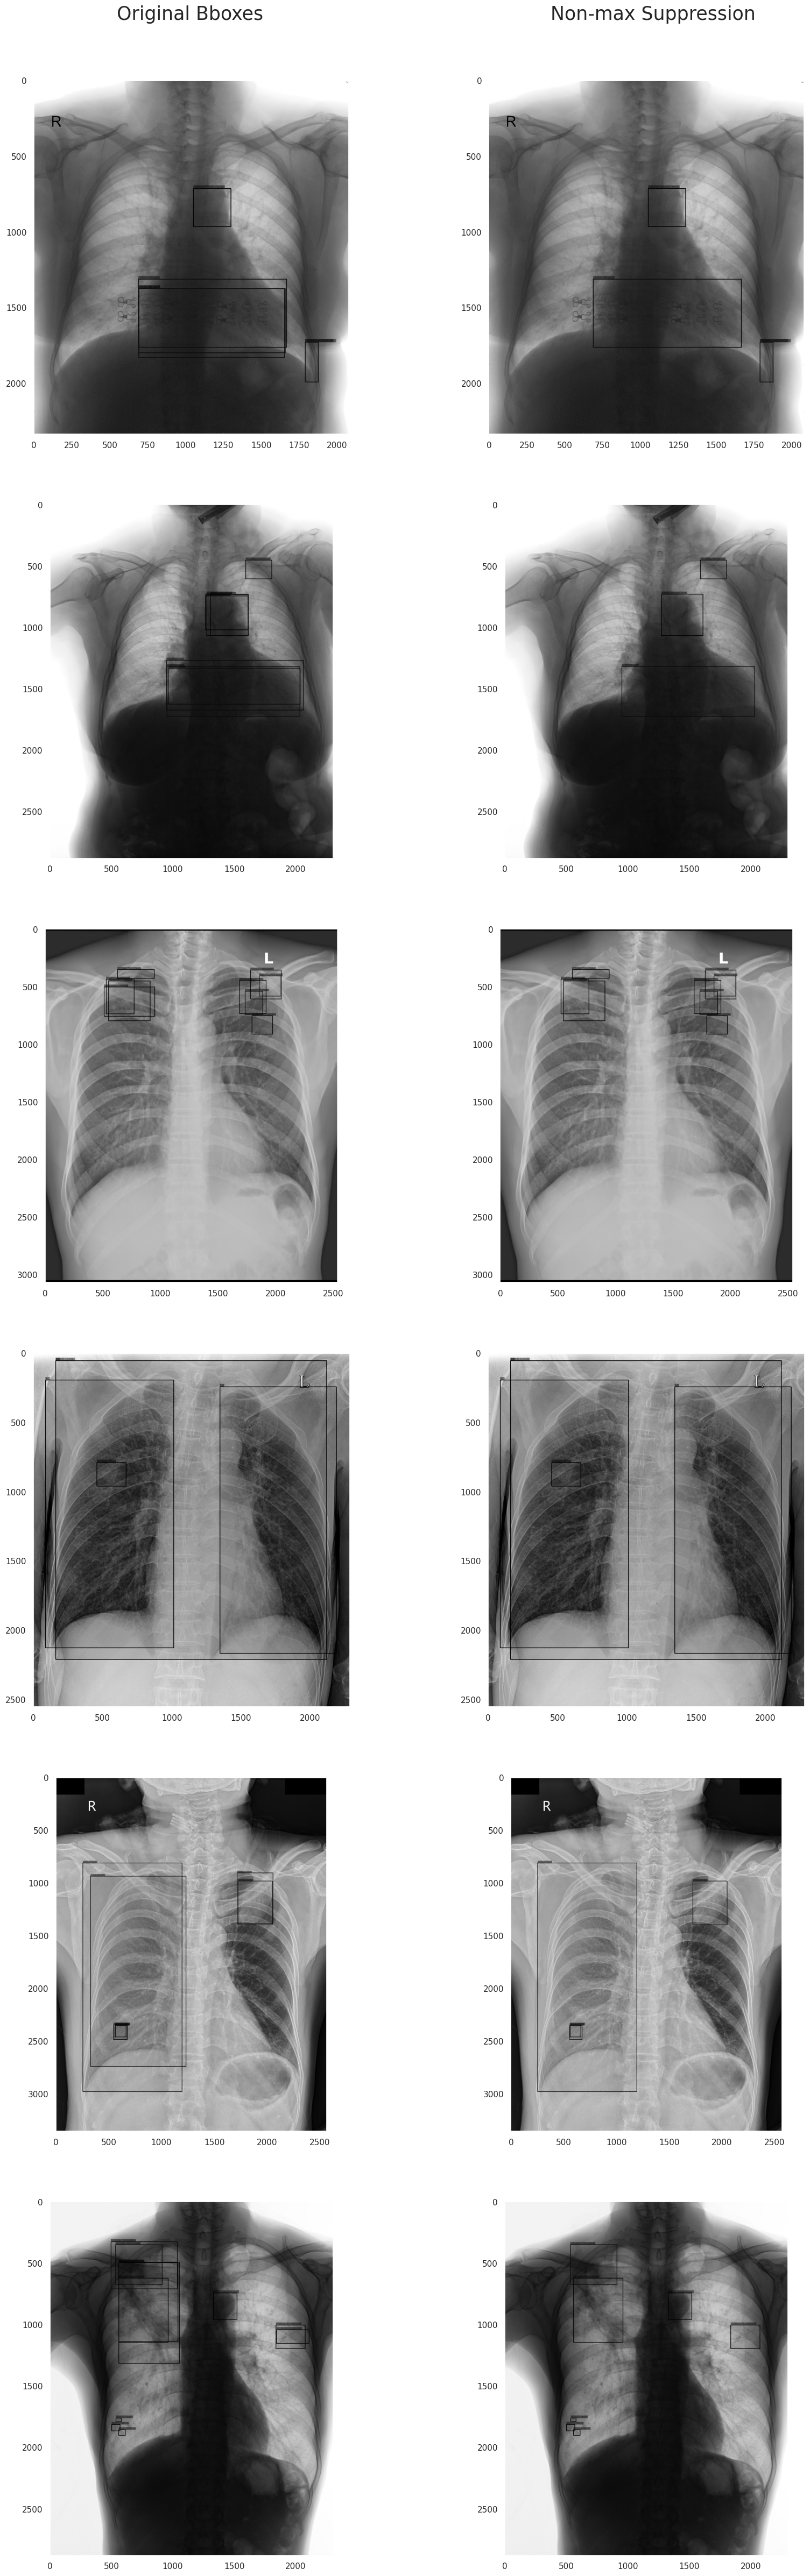

In [68]:
from ensemble_boxes import *

iou_thr = 0.5
skip_box_thr = 0.0001
viz_images = []

for img_id, path in zip(train_annotations['image_id'][:6], train_annotations['image_path'][:6]):
#     img_array  = cv2.imread(path)
    ds = pydicom.dcmread(path)
    img_array = ds.pixel_array
    image_basename = path.split('/')[-1].strip('.dicom')
#     image_basename = Path(path).stem
#     print(f"(\'{image_basename}\', \'{path}\')")
    img_annotations = train_annotations.loc[train_annotations['image_id'] == img_id]

    boxes_viz = img_annotations[['x_min', 'y_min', 'x_max', 'y_max']].to_numpy().tolist()
    labels_viz = img_annotations['class_id'].to_numpy().tolist()
    
    print("Bboxes before nms:\n", boxes_viz)
    print("Labels before nms:\n", labels_viz)
    
    ## Visualize Original Bboxes
    img_before = img_array.copy()
    for box, label in zip(boxes_viz, labels_viz):
        x_min, y_min, x_max, y_max = (box[0], box[1], box[2], box[3])
        color = label2color[int(label)]
        img_before = draw_bbox(img_before, list(np.int_(box)), viz_labels[label], color)
    viz_images.append(img_before)
    
    boxes_list = []
    scores_list = []
    labels_list = []
    weights = []
    
    boxes_single = []
    labels_single = []
    
    cls_ids = img_annotations['class_id'].unique().tolist()
    count_dict = Counter(img_annotations['class_id'].tolist())
    print(count_dict)

    for cid in cls_ids:       
        ## Performing Fusing operation only for multiple bboxes with the same label
        if count_dict[cid]==1:
            labels_single.append(cid)
            boxes_single.append(img_annotations[img_annotations.class_id==cid][['x_min', 'y_min', 'x_max', 'y_max']].to_numpy().squeeze().tolist())

        else:
            cls_list =img_annotations[img_annotations.class_id==cid]['class_id'].tolist()
            labels_list.append(cls_list)
            bbox = img_annotations[img_annotations.class_id==cid][['x_min', 'y_min', 'x_max', 'y_max']].to_numpy()
            ## Normalizing Bbox by Image Width and Height
            bbox = bbox/(img_array.shape[1], img_array.shape[0], img_array.shape[1], img_array.shape[0])
            bbox = np.clip(bbox, 0, 1)
            boxes_list.append(bbox.tolist())
            scores_list.append(np.ones(len(cls_list)).tolist())

            weights.append(1)
            
    # Perform NMS
    boxes, scores, box_labels = nms(boxes_list, scores_list, labels_list, weights=weights,
                                    iou_thr=iou_thr)
    
    boxes = boxes*(img_array.shape[1], img_array.shape[0], img_array.shape[1], img_array.shape[0])
    boxes = boxes.round(1).tolist()
    box_labels = box_labels.astype(int).tolist()

    boxes.extend(boxes_single)
    box_labels.extend(labels_single)
    
    print("Bboxes after nms:\n", boxes)
    print("Labels after nms:\n", box_labels)
    
    ## Visualize Bboxes after operation
    img_after = img_array.copy()
    for box, label in zip(boxes, box_labels):
        color = label2color[int(label)]
        img_after = draw_bbox(img_after, list(np.int_(box)), viz_labels[label], color)
    viz_images.append(img_after)
    print()
        
plot_imgs(viz_images, cmap='gray')
plt.figtext(0.3, 0.9,"Original Bboxes", va="top", ha="center", size=25)
plt.figtext(0.73, 0.9,"Non-max Suppression", va="top", ha="center", size=25)
# plt.savefig('nms.png', bbox_inches='tight')
plt.show()

## Get Labels for RL

In [136]:
def evaluate_model_accuracy(model, dataloader):
    """
    Evaluate the accuracy of a model on a given dataloader.

    Args:
        model (torch.nn.Module): The PyTorch model to evaluate.
        dataloader (torch.utils.data.DataLoader): Dataloader with the evaluation dataset.
        device (torch.device): The device to perform the evaluation on (CPU or GPU).

    Returns:
        float: The accuracy of the model as a percentage.
    """
    model.eval()  # Set the model to evaluation mode
    correct = 0
    total = 0
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model.to(device)

    with torch.no_grad():  # Disable gradient computation for evaluation
        for inputs, targets in tqdm(dataloader):
            # Move inputs and targets to the specified device
            inputs, targets = inputs.to(device), targets.to(device)

            # Forward pass to get predictions
            outputs = model(inputs)

            # Get predicted class (index of the maximum logit)
            _, predicted = torch.max(outputs, dim=1)

            # Update total and correct counts
            total += targets.size(0)
            correct += (predicted == targets).sum().item()

    # Calculate accuracy
    accuracy = (correct / total) * 100
    return accuracy

def get_wrong_predictions(model, dataloader):
    """
    Get the indices of wrongly predicted samples in the test dataset.

    Args:
        model (torch.nn.Module): The PyTorch model to evaluate.
        dataloader (torch.utils.data.DataLoader): Dataloader with the evaluation dataset.
        device (torch.device): The device to perform the evaluation on (CPU or GPU).

    Returns:
        list: A list of indices corresponding to wrongly predicted samples.
    """
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model.eval()
    model.to(device)
    wrong_indices = []
    prediction_list = []
    label_list = []

    with torch.no_grad():  # Disable gradient computation for evaluation
        for batch_idx, (inputs, targets) in enumerate(dataloader):
            # Move inputs and targets to the specified device
            inputs, targets = inputs.to(device), targets.to(device)

            # Forward pass to get predictions
            outputs = model(inputs)
            predictions = torch.sigmoid(outputs).float()  # Convert logits to binary predictions
            prediction_list.extend(predictions.cpu())
            label_list.extend(targets.cpu())
            # Get predicted class (index of the maximum logit)
            _, predicted = torch.max(outputs, dim=1)

            # Find indices of incorrect predictions
            wrong = (predicted != targets).nonzero(as_tuple=True)[0]

            # Map batch indices to dataset indices
            batch_start_idx = batch_idx * dataloader.batch_size
            wrong_indices_batch = wrong.cpu().numpy() + batch_start_idx

            # Append the wrong indices for this batch
            wrong_indices.extend(wrong_indices_batch)
            if batch_idx % 40 == 0:
                print(batch_idx)

    return wrong_indices, torch.stack(prediction_list, dim=0), torch.stack(label_list, dim=0)

In [137]:
import pydicom
import torch
import torchvision.models as models

# Load the pretrained ResNet-50 model
model = models.resnet50(pretrained=True)

num_classes = 15  # 14 abnormalities + "No finding"

# Modify the final fully connected layer to match the number of classes
model.fc = torch.nn.Linear(model.fc.in_features, num_classes)

model.load_state_dict(torch.load("../vu2/CXR-model.pth"))

# Move the model to the appropriate device (GPU or CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

# # Evaluate accuracy
# accuracy = evaluate_model_accuracy(model, val_loader)
# print(f"Model Accuracy Val: {accuracy:.2f}%")

# # Evaluate accuracy
# accuracy = evaluate_model_accuracy(model, test_loader)
# print(f"Model Accuracy Test: {accuracy:.2f}%")

# target_list, y_proba, y_test = get_wrong_predictions(model, val_loader)

/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [138]:
# # Save the list to a file
# with open("../vu2/RL4Auditing/CXR/val_target_list.pkl", "wb") as f:
#     pickle.dump(target_list, f)
# # Save the tensor to a file
# torch.save(y_proba, "../vu2/RL4Auditing/CXR/val_y_proba.pt")
# torch.save(y_test, "../vu2/RL4Auditing/CXR/val_y_test.pt")

## visualize the expl

In [71]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from captum.attr import LayerGradCam
from torchvision.transforms.functional import to_pil_image

def visualize_gradcam_overlay(model, image_tensor, target_layer, path, target_class=None, device="cuda"):
    """
    Visualize Grad-CAM with a heatmap overlayed on the original image.

    Args:
        model: PyTorch model.
        image_tensor: Input image tensor (1, C, H, W) normalized for the model.
        target_layer: Layer of the model to compute Grad-CAM (e.g., model.layer4[-1]).
        target_class: Target class index for explanation (default: model prediction).
        device: Device to run the computations on ("cuda" or "cpu").
    
    Returns:
        None (Displays the Grad-CAM visualization).
    """
    model = model.to(device)
    model.eval()

    # Ensure the input tensor is on the correct device
    image_tensor = image_tensor.to(device)

    # Set target class to the model prediction if not specified
    if target_class is None:
        with torch.no_grad():
            output = model(image_tensor)
            target_class = output.argmax(dim=1).item()

    # Initialize LayerGradCam for the target layer
    grad_cam = LayerGradCam(model, target_layer)

    # Compute Grad-CAM attributions
    attributions = grad_cam.attribute(image_tensor, target=target_class)

    # Upsample the attributions to the size of the input image
    upsampled_attributions = LayerGradCam.interpolate(attributions, image_tensor.shape[2:])
    heatmap = upsampled_attributions.squeeze(0).cpu().detach().numpy()  # Remove batch dimension and convert to numpy
    heatmap = np.maximum(heatmap, 0)  # ReLU to remove negative values
    heatmap /= heatmap.max()  # Normalize to [0, 1]
    heatmap = heatmap.squeeze(0)

    ds = pydicom.dcmread(path)
    input_image = ds.pixel_array
    input_image = cv2.resize(input_image, (224, 224))
#     input_image = input_image.astype(np.uint8)  # Convert uint16 to uint8 by truncation
#     # Convert the input tensor to an image
#     input_image = image_tensor.squeeze(0).cpu()  # Remove batch dimension
#     input_image = input_image.permute(1, 2, 0).detach().numpy()  # Convert to HWC format
#     input_image = (input_image - input_image.min()) / (input_image.max() - input_image.min())  # Normalize to [0, 1]

    # Overlay heatmap on the image
    plt.figure(figsize=(8, 8))
    plt.imshow(input_image, alpha=1.0, cmap='gray')  # Original image
    plt.imshow(heatmap, cmap="jet", alpha=0.5)  # Heatmap with transparency
    plt.axis("off")
    plt.title("Grad-CAM Heatmap Overlay")
    plt.show()


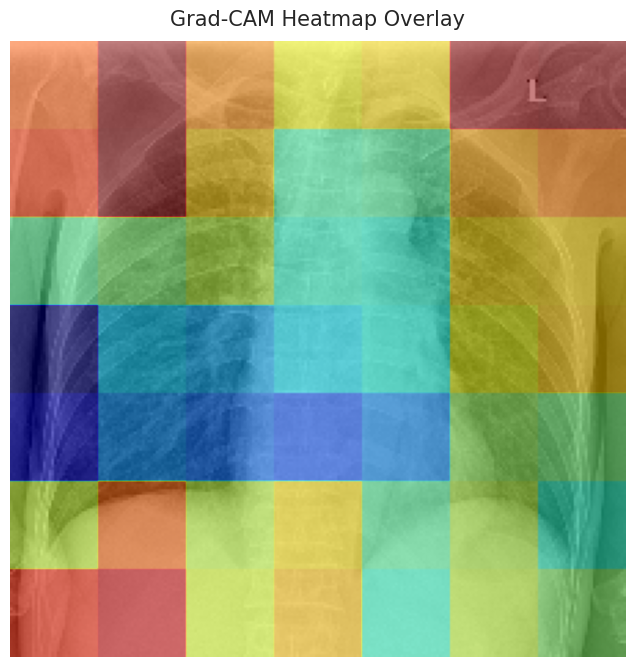

In [72]:
import torchvision.models as models
import torchvision.transforms as transforms
from PIL import Image

# Load a pretrained ResNet-50 model
model = models.resnet50(pretrained=True)

# Load and preprocess an image
# image_path = "path_to_your_image.jpg"
# image = Image.open(image_path).convert("RGB")
path = train_annotations['image_path'][6]
img_id = train_annotations['image_id'][6]
labels = train_annotations['class_id'][6]

ds = pydicom.dcmread(path)
img = ds.pixel_array
img = img.astype(np.uint8)  # Convert uint16 to uint8 by truncation

# Optionally normalize the pixel values to the [0, 255] range
img = cv2.normalize(img, None, 0, 255, cv2.NORM_MINMAX)

img = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)  # Convert to RGB
img = cv2.resize(img, (224, 224))  # Resize for VGG16

transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])
image_tensor = transform(img).unsqueeze(0)  # Add batch dimension

# Target layer for Grad-CAM (e.g., the last convolutional layer)
target_layer = model.layer4[-1]

# Visualize Grad-CAM
visualize_gradcam_overlay(model, image_tensor, target_layer, path)

## save expl

In [80]:
# import torch
# import torchvision.transforms as transforms
# from captum.attr import LayerGradCam
# import matplotlib.pyplot as plt

# import torch
# import torchvision.transforms as transforms
# from captum.attr import LayerGradCam
# import numpy as np
# import os

# def save_gradcam_explanations_to_single_npy(model, test_loader, target_layer, output_file):
#     """
#     Generate and save Grad-CAM explanations for all images in the test set to a single .npy file.

#     Args:
#         model (torch.nn.Module): The PyTorch model to be explained.
#         test_loader (torch.utils.data.DataLoader): The data loader for the test set.
#         target_layer (torch.nn.Module): The layer in the model for which Grad-CAM is computed.
#         output_file (str): File path to save the Grad-CAM explanations.

#     Returns:
#         None
#     """
#     # Ensure the model is in evaluation mode
#     device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
#     model.eval()
#     model.to(device)

#     explanations = {}
#     image_count = 0

#     # Iterate through the test set
#     for inputs, labels in tqdm(test_loader):
#         inputs, labels = inputs.to(device), labels.to(device)
#         for i in range(inputs.size(0)):
#             input_tensor = inputs[i:i+1]  # Select a single image
#             label = labels[i].item()

#             # Initialize LayerGradCam with the model and target layer
#             gradcam = LayerGradCam(model, target_layer)
#             with torch.no_grad():
#                 # Compute the target class
#                 output = model(input_tensor)
#                 target_class = torch.argmax(output, dim=1).item()

#             # Compute Grad-CAM attributions
#             attributions = gradcam.attribute(input_tensor, target=target_class)

#             # Upsample the attributions to match the input size
#             attributions = attributions.squeeze().cpu().detach().numpy()

#             # Normalize the attributions
#             attributions = (attributions - np.min(attributions)) / (np.max(attributions) - np.min(attributions))

#             # Add the explanation to the dictionary
#             explanations[image_count] = attributions

#             image_count += 1

#     # Save all explanations to a single .npy file
#     np.save(output_file, explanations)

## Load files 

In [139]:
# # Specify output file
# output_file = "../vu2/RL4Auditing/CXR/val_expls.npy"

# # Generate and save Grad-CAM explanations
# save_gradcam_explanations_to_single_npy(model, val_loader, target_layer, output_file)

with open("../vu2/RL4Auditing/CXR/val_target_list.pkl", "rb") as f:
    target_list = pickle.load(f)
# Save the tensor to a file
y_proba = torch.load("../vu2/RL4Auditing/CXR/val_y_proba.pt")
y_test = torch.load("../vu2/RL4Auditing/CXR/val_y_test.pt")

# Save the list to a file
with open("../vu2/RL4Auditing/CXR/test_target_list.pkl", "rb") as f:
    target4test_list = pickle.load(f)
# Save the tensor to a file
y4test_proba = torch.load("../vu2/RL4Auditing/CXR/test_y_proba.pt")
y4test = torch.load("../vu2/RL4Auditing/CXR/test_y_test.pt")


In [140]:
val_expl = np.load("../vu2/RL4Auditing/CXR/val_expls.npy", allow_pickle=True).item()
test_expl = np.load("../vu2/RL4Auditing/CXR/test_expls.npy", allow_pickle=True).item()

6338

In [ ]:
from ensemble_boxes import *

iou_thr = 0.5
skip_box_thr = 0.0001
viz_images = []

for img_id, path in zip(train_annotations['image_id'][:6], train_annotations['image_path'][:6]):
#     img_array  = cv2.imread(path)
    ds = pydicom.dcmread(path)
    img_array = ds.pixel_array
    image_basename = path.split('/')[-1].strip('.dicom')
#     image_basename = Path(path).stem
#     print(f"(\'{image_basename}\', \'{path}\')")
    img_annotations = train_annotations.loc[train_annotations['image_id'] == img_id]

    boxes_viz = img_annotations[['x_min', 'y_min', 'x_max', 'y_max']].to_numpy().tolist()
    labels_viz = img_annotations['class_id'].to_numpy().tolist()
    
    print("Bboxes before nms:\n", boxes_viz)
    print("Labels before nms:\n", labels_viz)
    
    ## Visualize Original Bboxes
    img_before = img_array.copy()
    for box, label in zip(boxes_viz, labels_viz):
        x_min, y_min, x_max, y_max = (box[0], box[1], box[2], box[3])
        color = label2color[int(label)]
        img_before = draw_bbox(img_before, list(np.int_(box)), viz_labels[label], color)
    viz_images.append(img_before)
    
    boxes_list = []
    scores_list = []
    labels_list = []
    weights = []
    
    boxes_single = []
    labels_single = []
    
    cls_ids = img_annotations['class_id'].unique().tolist()
    count_dict = Counter(img_annotations['class_id'].tolist())
    print(count_dict)

    for cid in cls_ids:       
        ## Performing Fusing operation only for multiple bboxes with the same label
        if count_dict[cid]==1:
            labels_single.append(cid)
            boxes_single.append(img_annotations[img_annotations.class_id==cid][['x_min', 'y_min', 'x_max', 'y_max']].to_numpy().squeeze().tolist())

        else:
            cls_list =img_annotations[img_annotations.class_id==cid]['class_id'].tolist()
            labels_list.append(cls_list)
            bbox = img_annotations[img_annotations.class_id==cid][['x_min', 'y_min', 'x_max', 'y_max']].to_numpy()
            ## Normalizing Bbox by Image Width and Height
            bbox = bbox/(img_array.shape[1], img_array.shape[0], img_array.shape[1], img_array.shape[0])
            bbox = np.clip(bbox, 0, 1)
            boxes_list.append(bbox.tolist())
            scores_list.append(np.ones(len(cls_list)).tolist())

            weights.append(1)
            
    # Perform NMS
    boxes, scores, box_labels = nms(boxes_list, scores_list, labels_list, weights=weights,
                                    iou_thr=iou_thr)
    
    boxes = boxes*(img_array.shape[1], img_array.shape[0], img_array.shape[1], img_array.shape[0])
    boxes = boxes.round(1).tolist()
    box_labels = box_labels.astype(int).tolist()

    boxes.extend(boxes_single)
    box_labels.extend(labels_single)
    
    print("Bboxes after nms:\n", boxes)
    print("Labels after nms:\n", box_labels)
    
    ## Visualize Bboxes after operation
    img_after = img_array.copy()
    for box, label in zip(boxes, box_labels):
        color = label2color[int(label)]
        img_after = draw_bbox(img_after, list(np.int_(box)), viz_labels[label], color)
    viz_images.append(img_after)
    print()
        
plot_imgs(viz_images, cmap='gray')
plt.figtext(0.3, 0.9,"Original Bboxes", va="top", ha="center", size=25)
plt.figtext(0.73, 0.9,"Non-max Suppression", va="top", ha="center", size=25)
# plt.savefig('nms.png', bbox_inches='tight')
plt.show()